In [1]:
import sys
sys.path.append("/hlabhome/wg-mjames/git/Toby_work")
import pandas as pd
import numpy as np
import elephant
from scipy import stats,signal,integrate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn import metrics, preprocessing
from sklearn.feature_selection import RFE
import imblearn
from imblearn import over_sampling
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import ks_2samp
import pickle
import random
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from graphical_functions import *
from helper_functions_math_addons import *
from helper_functions_file_handling import *
from helper_functions_modeling import *
from sklearn.utils.class_weight import compute_sample_weight
%load_ext autoreload
%autoreload 2
import os
NCPU = "4"
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['VECLIB_MAXIMUM_THREADS'] = '4'
os.environ['NUMEXPR_NUM_THREADS'] = '4'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.family':'DejaVu Sans'})

In [2]:
split_thres = (0.6, 0.8)
addon = 'unfiltered'
downlims = [10,4,10]
load_data = True

train_scaled, test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, downlims)

Loaded successfully


In [4]:
train_scaled

,ifr,mean_isis,median_isis,max_isis,min_isis,sd,cv,cv2,lv,lvr,state,cell,animal,region,celltype,spike_num,state_spikes,state_length,state_start_end
0,-0.442009,0.048498,0.241415,0.001186,-0.180359,0.001143,-0.149785,-0.259158,-0.244537,-0.244537,2,caf69_358_1228_0_12_0_wt,caf69,ACad,RSU,500,40954,3320,"[0.00532, 47.99792]"
1,-0.219854,-0.511334,-0.339192,-0.627752,0.965794,-0.609030,-0.743285,-0.755651,-0.851785,-0.851785,2,caf69_358_1228_0_12_0_wt,caf69,ACad,RSU,500,40954,3320,"[47.99792, 85.89536]"
2,1.264809,-0.598747,-0.923910,-0.428243,-0.868051,-0.441573,0.944319,1.109833,1.126746,1.126746,2,caf69_358_1228_0_12_0_wt,caf69,ACad,RSU,500,40954,3320,"[85.89536, 120.96736]"
3,1.262532,-0.389581,-0.637719,0.294429,-0.982667,-0.158196,1.347756,0.859262,0.990695,0.990695,2,caf69_358_1228_0_12_0_wt,caf69,ACad,RSU,500,40954,3320,"[120.96736, 158.8382]"
4,0.088154,-0.180928,-0.136062,-0.281265,-0.524205,-0.178620,0.028413,0.689620,0.638585,0.638585,2,caf69_358_1228_0_12_0_wt,caf69,ACad,RSU,500,40954,3320,"[158.8382, 206.37044]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1791239,0.097129,0.098287,-0.041075,1.214622,-0.749313,0.267896,0.994285,1.167325,1.268030,1.268030,1,bth100_99_0624_12_24_94_wt,bth100,V1,RSU,500,1313,96,"[40076.01968, 40105.42356]"
1791240,-0.663702,0.334793,0.160682,-0.294729,-0.500610,0.141016,-0.515616,0.047788,0.183194,0.183194,1,bth100_99_0624_12_24_94_wt,bth100,V1,RSU,500,1313,96,"[40105.42356, 40140.88016]"
1791241,1.072195,-0.496235,-0.613089,0.111844,-0.749313,-0.370441,0.669149,0.829188,0.678256,0.678256,1,bth100_99_0624_12_24_94_wt,bth100,V1,RSU,500,1946,72,"[42492.06728, 42511.10384]"
1791242,1.892323,-0.678761,-0.743898,-0.782311,-0.500610,-0.640206,-0.180194,0.348175,0.194636,0.194636,1,bth100_99_0624_12_24_94_wt,bth100,V1,RSU,500,1946,72,"[42511.10384, 42525.95744]"


In [3]:
train_scaled.cell.unique()

<ArrowStringArray>
[  'caf69_358_1228_0_12_0_wt',   'caf69_358_1228_0_12_1_wt',
   'caf69_358_1228_0_12_2_wt',   'caf69_358_1228_0_12_3_wt',
   'caf69_358_1228_0_12_4_wt',   'caf69_358_1228_0_12_5_wt',
   'caf69_358_1228_0_12_6_wt',   'caf69_358_1228_0_12_7_wt',
   'caf69_358_1228_0_12_8_wt',   'caf69_358_1228_0_12_9_wt',
 ...
 'bth100_99_0624_12_24_85_wt', 'bth100_99_0624_12_24_86_wt',
 'bth100_99_0624_12_24_87_wt', 'bth100_99_0624_12_24_88_wt',
 'bth100_99_0624_12_24_89_wt', 'bth100_99_0624_12_24_90_wt',
 'bth100_99_0624_12_24_91_wt', 'bth100_99_0624_12_24_92_wt',
 'bth100_99_0624_12_24_93_wt', 'bth100_99_0624_12_24_94_wt']
Length: 4317, dtype: str

In [29]:
train_scaled

,ifr,mean_isis,median_isis,max_isis,min_isis,sd,cv,cv2,lv,lvr,state,cell,animal,region,celltype,spike_num,state_spikes,state_length,state_start_end
0,-0.442009,0.048498,0.241415,0.001186,-0.180359,0.001143,-0.149785,-0.259158,-0.244537,-0.244537,2,caf69_358_1228_0_12_0_wt,caf69,ACC,RSU,500,40954,3320,"[0.00532, 47.99792]"
1,-0.219854,-0.511334,-0.339192,-0.627752,0.965794,-0.609030,-0.743285,-0.755651,-0.851785,-0.851785,2,caf69_358_1228_0_12_0_wt,caf69,ACC,RSU,500,40954,3320,"[47.99792, 85.89536]"
2,1.264809,-0.598747,-0.923910,-0.428243,-0.868051,-0.441573,0.944319,1.109833,1.126746,1.126746,2,caf69_358_1228_0_12_0_wt,caf69,ACC,RSU,500,40954,3320,"[85.89536, 120.96736]"
3,1.262532,-0.389581,-0.637719,0.294429,-0.982667,-0.158196,1.347756,0.859262,0.990695,0.990695,2,caf69_358_1228_0_12_0_wt,caf69,ACC,RSU,500,40954,3320,"[120.96736, 158.8382]"
4,0.088154,-0.180928,-0.136062,-0.281265,-0.524205,-0.178620,0.028413,0.689620,0.638585,0.638585,2,caf69_358_1228_0_12_0_wt,caf69,ACC,RSU,500,40954,3320,"[158.8382, 206.37044]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1791239,0.097129,0.098287,-0.041075,1.214622,-0.749313,0.267896,0.994285,1.167325,1.268030,1.268030,1,bth100_99_0624_12_24_94_wt,bth100,V1,RSU,500,1313,96,"[40076.01968, 40105.42356]"
1791240,-0.663702,0.334793,0.160682,-0.294729,-0.500610,0.141016,-0.515616,0.047788,0.183194,0.183194,1,bth100_99_0624_12_24_94_wt,bth100,V1,RSU,500,1313,96,"[40105.42356, 40140.88016]"
1791241,1.072195,-0.496235,-0.613089,0.111844,-0.749313,-0.370441,0.669149,0.829188,0.678256,0.678256,1,bth100_99_0624_12_24_94_wt,bth100,V1,RSU,500,1946,72,"[42492.06728, 42511.10384]"
1791242,1.892323,-0.678761,-0.743898,-0.782311,-0.500610,-0.640206,-0.180194,0.348175,0.194636,0.194636,1,bth100_99_0624_12_24_94_wt,bth100,V1,RSU,500,1946,72,"[42511.10384, 42525.95744]"


In [4]:
graphic_train = get_extended_condensed_data(train_scaled)
#graphic_test = get_extended_condensed_data(test_scaled)

In [5]:
models = train_multi_models(train_scaled, sampling_types=['over'], methods=['LogReg'])
cms = get_cms_multi(test_scaled, models, get_spiking=True)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4316/4316 [00:25<00:00, 171.06it/s]


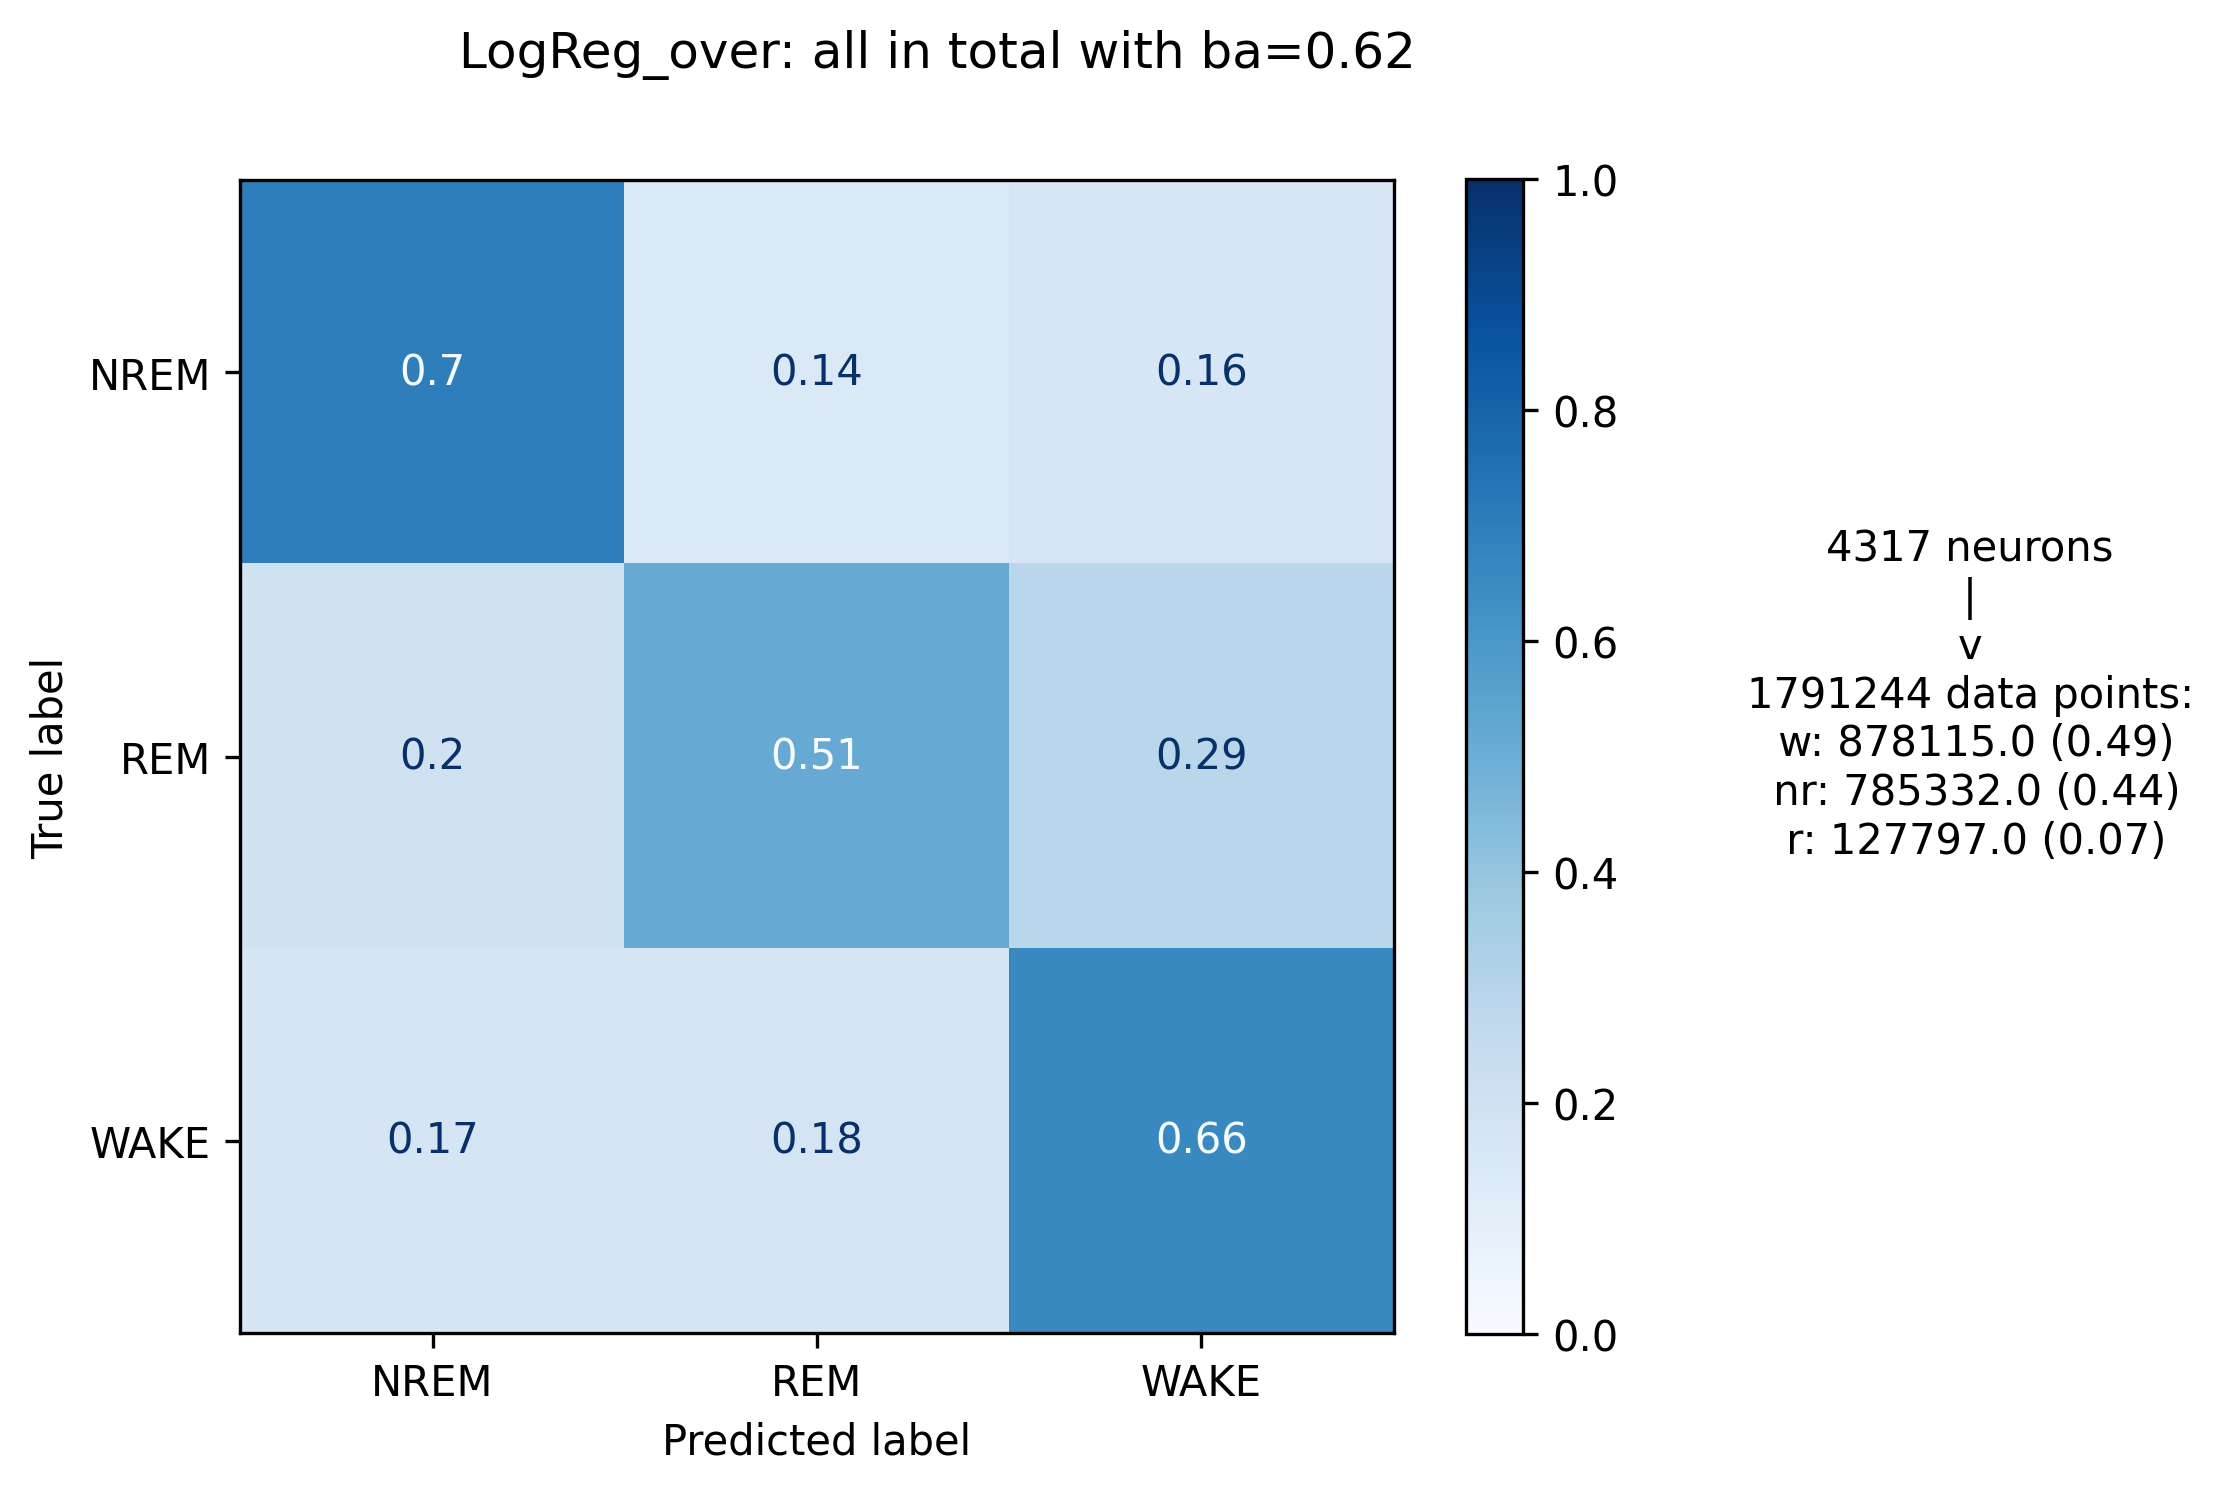

In [6]:
for key, val in cms.items():
    get_mean_cms_visual(val, graphic_train, key, by_geno=False, by_age=False, subplot_kwargs={'figsize':(6.2,5), 'dpi':300}, 
                        addon_text=True, addon_suff='poster', parent_file_p='', savefig=False)

In [15]:
for cm in cms.values():
    for cell, spec_cell in cm.items():
        print(cell, spec_cell[-1])

caf69_358_1228_0_12_0_wt 0        [32104.0294, 32126.2874]
1       [32126.2874, 32154.36484]
2      [32154.36484, 32179.22556]
3      [32179.22556, 32205.10504]
4      [32205.10504, 32231.70104]
                  ...            
195    [27280.11412, 27339.86484]
196    [27339.86484, 27398.90716]
197    [28160.28872, 28219.69184]
198    [28360.06388, 28419.81092]
199    [28620.22684, 28659.65624]
Name: state_start_end, Length: 200, dtype: object
caf69_358_1228_0_12_1_wt 200    [32106.07712, 32202.90864]
201     [32356.8808, 32361.10852]
202    [34500.46256, 34695.35572]
203    [34695.35572, 34812.15896]
204    [34812.15896, 34930.48752]
205    [34930.48752, 34997.94636]
206      [34997.94636, 35067.913]
207       [35067.913, 35282.8424]
208    [35369.19576, 35399.85772]
209    [35416.17188, 35554.96816]
210     [35708.6914, 35812.22472]
211    [35812.22472, 35886.23064]
212    [35886.23064, 36003.53512]
213    [37453.02232, 37511.28088]
214    [37520.34756, 37654.62072]
215    [37654.62

caf69_361_1230_12_24_4_wt 50433    [14280.38304, 14399.13928]
50434      [18000.3052, 18031.2598]
50435    [19052.32588, 19063.89088]
50436    [19097.77048, 19100.87192]
50437     [19304.5072, 19343.80432]
50438    [19376.79588, 19387.84396]
50439    [33320.08532, 33333.31052]
50440      [33448.05364, 33450.131]
50441     [33489.1926, 33499.80656]
50442      [33822.977, 33830.44852]
50443     [30480.0344, 30593.99696]
50444    [30593.99696, 30753.59424]
50445    [30983.08712, 31234.57252]
50446    [31760.13504, 31949.95884]
50447    [32081.80128, 32654.91892]
50448    [32720.36404, 32978.42636]
50449    [33060.55772, 33276.97228]
50450    [33960.01196, 34235.98196]
50451    [35080.73396, 35333.77992]
50452     [35333.77992, 35507.0868]
50453     [35507.0868, 35813.98112]
50454    [35813.98112, 35899.83692]
50455    [35899.83692, 35960.52752]
50456    [35960.52752, 36125.76756]
50457    [36125.76756, 36203.38616]
50458    [36203.38616, 36261.96028]
50459    [36261.96028, 36432.85484]
50

caf69_361_1230_12_24_149_wt 62878      [18000.13804, 18031.961]
62879    [18944.06992, 18947.97852]
62880     [19052.2578, 19063.56616]
62881    [19092.17308, 19107.98904]
62882    [19304.45076, 19343.78324]
62883    [19376.46596, 19387.83204]
62884      [33320.73732, 33335.949]
62885     [33448.1924, 33451.89036]
62886      [33488.3054, 33499.9484]
62887    [33704.22716, 33727.87016]
62888     [33820.52796, 33831.8332]
62889      [30480.3248, 30572.7788]
62890     [30572.7788, 30663.04848]
62891    [30663.04848, 30752.00664]
62892    [30980.06944, 31119.09956]
62893    [31119.09956, 31240.35992]
62894    [31240.35992, 31374.45728]
62895    [31374.45728, 31509.36496]
62896     [31509.36496, 31622.0294]
62897    [31760.15204, 31868.12868]
62898    [32080.02816, 32193.49424]
62899    [32193.49424, 32326.77564]
62900    [32326.77564, 32483.01396]
62901    [32483.01396, 32627.01664]
62902     [32720.37064, 32863.3994]
62903    [33060.05376, 33188.48088]
62904     [33960.0976, 34107.58968]


caf71_492_0103_0_12_103_app_ps1 69734    [29608.18964, 29683.73896]
69735    [29712.00144, 29823.08488]
69736    [29856.17796, 29871.74556]
69737    [29904.05484, 30047.22564]
69738    [30104.34192, 30143.92104]
69739    [30280.05856, 30391.63688]
69740    [30420.44256, 30503.88608]
69741    [30532.58972, 30547.69308]
69742    [30616.04636, 30679.74044]
69743    [30712.00948, 30719.83736]
69744    [30748.14568, 30791.84044]
69745    [30824.08856, 30831.93772]
69746    [30876.23472, 30907.66176]
69747    [30936.20392, 30943.24948]
69748     [31032.66552, 31067.8104]
69749     [31104.39644, 31123.7744]
69750    [31636.22624, 31703.92616]
69751     [31792.0434, 31803.68916]
69752    [31832.13408, 31859.54092]
69753    [32032.07916, 32035.98824]
69754     [32064.2996, 32083.86496]
69755    [32124.37232, 32159.94132]
69756    [32461.18508, 32491.61824]
69757    [32636.03804, 32639.84748]
69758    [32776.01712, 32799.84832]
69759    [32836.19004, 32859.66932]
69760    [33180.11604, 33263.633

caf73_381_0120_4_15_49_app_ps1 87117     [35764.26328, 35812.6424]
87118      [35864.0192, 35887.9992]
87119    [35960.02048, 35995.85924]
87120    [36004.07828, 36045.12624]
87121    [38704.02544, 38727.75028]
87122    [20898.51664, 21377.89548]
87123    [23190.75592, 25297.08368]
87124    [25392.81272, 25770.23868]
87125     [27109.19936, 28719.9276]
87126     [28731.0748, 29095.53684]
87127    [29224.89928, 30441.63924]
87128     [30613.04888, 31482.0256]
87129    [31610.13808, 32551.14004]
87130    [32551.14004, 32756.91512]
87131    [32756.91512, 32919.08064]
87132    [32919.08064, 33164.30664]
87133    [33164.30664, 33455.58884]
87134    [33455.58884, 33997.46672]
87135    [33997.46672, 34527.05728]
87136     [34527.05728, 34721.8832]
87137     [34812.2768, 34926.51308]
87138    [34926.51308, 35078.10276]
87139    [35078.10276, 35258.00108]
87140    [35258.00108, 35367.15376]
87141    [35367.15376, 35434.35384]
87142     [35434.35384, 35531.5026]
87143     [35531.5026, 35588.2750

...

zbr118_100_0522_12_24_107_app_ps1 403607       [29096.146, 29170.6342]
403608     [29170.6342, 29322.80224]
403609     [29322.80224, 29588.1378]
403610     [29588.1378, 29661.01688]
403611    [29661.01688, 29723.10864]
403612    [29723.10864, 29790.26648]
403613    [29790.26648, 29888.80544]
403614     [29888.80544, 30022.5276]
403615     [30022.5276, 30167.19652]
403616    [30167.19652, 30380.99324]
403617    [33468.04464, 33635.15032]
403618    [33635.15032, 33800.08948]
403619    [33800.08948, 33904.75868]
403620    [33904.75868, 33980.56492]
403621    [28336.61724, 28440.74216]
403622    [28440.74216, 28563.01856]
403623      [28563.01856, 28693.793]
403624      [28693.793, 28838.27696]
403625    [30549.31932, 30705.16276]
403626    [30924.06652, 31164.23352]
403627      [31484.9166, 31698.3076]
403628    [31850.22164, 32078.49392]
403629    [32078.49392, 32294.60668]
403630    [32568.76096, 32766.37244]
403631    [32964.02912, 33168.89976]
403632    [34060.15312, 34177.29896]
4036

zbr119_113_0604_12_19_137_app_ps1 441598    [19408.30272, 19546.93292]
441599    [19546.93292, 19634.54612]
441600    [19634.54612, 19724.92352]
441601    [19724.92352, 19832.42892]
441602    [19832.42892, 19931.83528]
441603    [19931.83528, 20026.94048]
441604    [20026.94048, 20124.67192]
441605    [20556.55232, 20664.82656]
441606    [20664.82656, 20786.74236]
441607    [20786.74236, 20889.55124]
441608     [20889.55124, 20989.8904]
441609     [20989.8904, 21110.18064]
441610    [21110.18064, 21198.83492]
441611    [21198.83492, 21295.15756]
441612    [21295.15756, 21384.18504]
441613    [21384.18504, 21478.78908]
441614    [21478.78908, 21607.84848]
441615    [21607.84848, 21755.36684]
441616    [21755.36684, 21912.31776]
441617     [21912.31776, 22012.5846]
441618      [22012.5846, 22107.6916]
441619      [22107.6916, 22216.6854]
441620     [22216.6854, 22320.60372]
441621      [22320.60372, 22414.906]
441622      [22414.906, 22526.32008]
441623    [22526.32008, 22634.61576]
4416

bth90_102_0323_12_24_59_wt 465196    [30916.61628, 31123.90428]
465197    [35052.92656, 35442.27512]
465198     [36669.3724, 36863.58648]
465199     [37132.0102, 37387.98292]
465200    [31124.05092, 31337.81604]
465201     [31450.39968, 31662.3398]
465202      [31662.3398, 31890.9312]
465203    [32268.38876, 32473.50512]
465204    [32473.50512, 32645.13312]
465205     [32645.13312, 32860.5252]
465206     [32860.5252, 33071.62892]
465207    [33071.62892, 33283.93504]
465208    [33564.81988, 33885.13136]
465209     [34232.14608, 34458.2764]
465210     [34689.24476, 34893.7566]
465211    [34912.63156, 35051.22156]
465212     [35724.10356, 35954.2352]
465213    [36272.07312, 36496.77928]
465214    [31412.77172, 31427.41304]
465215    [32088.21472, 32242.69012]
465216    [34000.03408, 34002.81644]
465217     [34516.0688, 34547.56972]
465218    [36184.70388, 36251.61088]
465219    [36608.42096, 36667.43072]
Name: state_start_end, dtype: object
bth90_102_0323_12_24_60_wt 465220    [30919.9789

bth95_105_0611_0_12_105_wt 482142      [33402.4696, 34027.1044]
482143    [34161.53228, 34323.16376]
482144     [35328.1834, 35907.24516]
482145    [16952.06836, 17073.29448]
482146    [17073.29448, 17232.46764]
482147    [17232.46764, 17405.11944]
482148     [17405.11944, 17510.2278]
482149     [17848.0034, 17909.93244]
482150     [20016.00024, 20054.2006]
482151     [20054.2006, 20124.64084]
482152    [20124.64084, 20271.67348]
482153     [20271.67348, 20430.3658]
482154    [20522.18424, 20707.75984]
482155    [20707.75984, 20937.83144]
482156     [21036.24124, 21231.4402]
482157    [21520.04076, 21644.58832]
482158      [21644.58832, 21772.382]
482159      [21772.382, 21945.13964]
482160    [21945.13964, 22012.28996]
482161     [22156.3632, 22201.70668]
482162    [22272.02744, 22318.64272]
482163    [28196.09024, 28259.39744]
482164    [28259.39744, 28351.56404]
482165     [28351.56404, 28442.7554]
482166     [28442.7554, 28526.89016]
482167    [28716.04016, 28780.35512]
482168    [

bth100_98_0624_0_12_1_wt 504253    [24102.74724, 24218.75952]
504254    [24218.75952, 24350.20864]
504255    [24350.20864, 24536.42056]
504256    [24536.42056, 24686.30592]
504257    [26200.76164, 26714.05924]
504258     [26714.05924, 27073.0998]
504259       [27073.0998, 27332.032]
504260       [27332.032, 27476.4026]
504261    [28306.53084, 28636.78428]
504262    [29264.08344, 29634.34012]
504263     [29634.34012, 29841.0358]
504264     [29841.0358, 30038.15284]
504265    [30038.15284, 30157.77364]
504266    [30157.77364, 30265.83008]
504267     [30265.83008, 30377.2022]
504268     [30377.2022, 30484.82184]
504269    [30484.82184, 30618.18876]
504270    [30618.18876, 30738.03416]
504271    [30738.03416, 30924.83384]
504272    [23407.26052, 23919.78684]
504273     [24760.74168, 24929.3404]
504274    [24982.37484, 25345.66928]
504275    [25436.89632, 25617.16372]
504276    [25712.02984, 25947.74976]
504277     [26055.06516, 26198.5034]
504278     [27717.1062, 28108.20176]
504279    [28

In [115]:
graphic_train

,index,state,region,cell,animal,celltype,geno,cell_no,age,age_group,state_str,cell_state,state_chunks
0,0,2,ACC,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,2,caf69_358_1228_0_12_0_wt-2,414
1,414,0,ACC,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,0,caf69_358_1228_0_12_0_wt-0,137
2,551,1,ACC,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,1,caf69_358_1228_0_12_0_wt-1,40
3,591,2,ACC,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,2,caf69_358_1228_0_12_1_wt-2,66
4,657,0,ACC,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,0,caf69_358_1228_0_12_1_wt-0,44
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12945,1789623,0,V1,bth100_99_0624_12_24_93_wt,bth100,FS,wt,93,99,young,0,bth100_99_0624_12_24_93_wt-0,528
12946,1790151,1,V1,bth100_99_0624_12_24_93_wt,bth100,FS,wt,93,99,young,1,bth100_99_0624_12_24_93_wt-1,84
12947,1790235,2,V1,bth100_99_0624_12_24_94_wt,bth100,RSU,wt,94,99,young,2,bth100_99_0624_12_24_94_wt-2,818
12948,1791053,0,V1,bth100_99_0624_12_24_94_wt,bth100,RSU,wt,94,99,young,0,bth100_99_0624_12_24_94_wt-0,165


In [7]:
def predict_full_animal(animal, models, cms, condensed_dataset, interval=0):
    cell_base_dir = '/media/HlabShare/appps1_cortical_communication_samb/appps1/data/'
    sleepnpy_base_dir = '/media/HlabShare/appps1_cortical_communication_samb/appps1/data/'
    cell_dir, sleepnpy_dir = get_dirs(animal, cell_base_dir, sleepnpy_base_dir)
    #print(sleepnpy_dir)
    valid_days = {'caf69':'', 'caf71':'0103','caf73':'0120','caf74':'0125', 'caf75':'0125',
             'caf77':'0202','caf81':'0304','caf82':'0304',
             'zbr106':'0223','zbr113':'0513','zbr114':'0426','zbr117':'','zbr118':'0522',
             'zbr119':'0604','bth90':'0323','bth95':'0611','bth100':'0624'}
    sleep_to_predictions = {1:2, 2:0, 3:1}
    sleep_states_files = {}
    all_dfs = {}
    for file in sleepnpy_dir:
        if valid_days[animal] in file:
            out = {'real':[], 'predictions':[], 'confidences':[], 'length':[], 'start':[], 'end':[],
                  'hits':[]}
            ind = os.path.basename(file)[:-10].lower()
            file_name = ind
            these_sleep_times = get_sleeptimes(file)
            these_sleep_times.sleepstate = these_sleep_times.sleepstate.replace(4, 1)
            these_sleep_times.sleepstate = these_sleep_times.sleepstate.replace(5, 1)
            these_sleep_times =these_sleep_times[these_sleep_times.sleepstate!=0]
            starts = list(these_sleep_times.start_time)
            ends = list(these_sleep_times.stop_time)
            reals = list(these_sleep_times.sleepstate)
            inserts = np.zeros(len(starts))
            if interval:
                for i, start in enumerate(starts):
                    length = ends[i]-start
                    inserts[i] = int((length-1)//interval)
                added=0
                for i, val in enumerate(inserts):
                    if val:
                        ends[i+added] = starts[i+added]+interval
                    while added<val:
                        added+=1
                        to_ind = i+added
                        starts.insert(to_ind,starts[to_ind-1]+interval)
                        ends.insert(to_ind, ends[to_ind-1]+interval)
                        reals.insert(to_ind, reals[to_ind-1])
            cells = condensed_dataset[(condensed_dataset.animal==animal)&(
                condensed_dataset.cell.str.contains(("_".join(ind.split("_")[-3:]))))].cell.unique()
            overall_predictions = np.zeros((len(starts), 3))
            confidence_predictions = np.zeros((len(starts), 3))
            timings_hits = np.zeros((len(starts)), dtype=object)
            for i, cell in enumerate(cells):
                spec_model = None
                for model in models:
                    if model['cell']==cell:
                        spec_model = model
                        break
                if not spec_model:
                    print(f'lol {cell} sucks, skipping')
                    continue
                timings = cms[cell][-1]
                predictions = cms[cell][2]
                confidences = cms[cell][5]
                for ind, timing in enumerate(timings):
                    spot = np.searchsorted(starts, timing[0], side='right')
                    overall_predictions[spot-1,predictions[ind]] += 1
                    confidence_predictions[spot-1, predictions[ind]] += confidences[ind][predictions[ind]]
                    if isinstance(timings_hits[spot-1], int):
                        timings_hits[spot-1] = [timing]
                    else: 
                        timings_hits[spot-1].append(timing)
            for index in range(len(overall_predictions)):
                out['real'].append(sleep_to_predictions[reals[index]])
                out['start'].append(starts[index])
                out['end'].append(ends[index])
                out['predictions'].append(overall_predictions[index])
                out['confidences'].append(confidence_predictions[index])
                out['length'].append(ends[index] - starts[index])
                out['hits'].append(timings_hits[index])
            out = pd.DataFrame(out)
            all_dfs[file_name] = out
    #print(all_dfs[file_name][all_dfs[file_name].length > 60])
    return all_dfs

In [8]:
def get_all_animal_accuracy(min_predictions_to_include=10, time_correction_by_file=True, time_norm_animal=True,
                           interval=0):
    combined = pd.DataFrame()
    anim_cms = {}
    for animal in tqdm(graphic_train.animal.unique()):
        all_dfs = predict_full_animal(animal, models['LogReg_over'], cms['LogReg_over'], graphic_train,
                                     interval=interval)
        animal_df = pd.DataFrame()
        prev_max=0
        for key, df in all_dfs.items():
            #print(key)
            pred_b = []
            pred_c = []
            total_pred = []
            for i, row in df.iterrows():
                pred_b.append(list(row['predictions']).index(max(row['predictions'])))
                pred_c.append(list(row['confidences']).index(max(row['confidences'])))
                total_pred.append(sum(row['predictions']))
            df['pred_b'] = pred_b
            df['pred_c'] = pred_c
            df['pred_num'] = df.predictions.apply(sum)
            avg_conf = []
            for i, row in df.iterrows():
                avg_conf.append([0 if not row.predictions[ind] else row.confidences[ind]/row.predictions[ind] for ind in range(3)])
            df['avg_conf']=avg_conf
            df['file'] = key
            df = df[df.pred_num>min_predictions_to_include].reset_index()
            if(len(df)):
                if prev_max and time_correction_by_file:
                    m = min(df.start)
                    df['start'] += prev_max - m
                    df['end'] += prev_max - m
                    df.hits = df['hits'].apply(lambda x: [[j[0]+prev_max-m, j[1]+prev_max-m] for j in x])
                prev_max = max(df['end'])
                animal_df = pd.concat([animal_df, df])
        animal_df = animal_df.reset_index()
        animal_df['animal'] = animal
        animal_df['geno'] = graphic_train[graphic_train.animal==animal].iloc[0].geno
        animal_df['age'] = graphic_train[graphic_train.animal==animal].iloc[0].age_group
        animal_df['cell'] = animal_df.animal + animal_df.index.astype(str)
        if time_norm_animal:
            m = min(animal_df.start)
            animal_df['end'] -= m
            animal_df['start'] -= m
            animal_df.hits = animal_df['hits'].apply(lambda x: [[j[0]-m, j[1]-m] for j in x])
        combined = pd.concat([animal_df, combined])
        anim_cms[animal] = metrics.confusion_matrix(animal_df.real, animal_df.pred_b, normalize="true")
    return combined, anim_cms

In [9]:
combined, anim_cms = get_all_animal_accuracy(time_correction_by_file=True, time_norm_animal=True, interval=0,
                                            min_predictions_to_include=4)

 47%|███████████████████████████████████████████████████████                                                              | 8/17 [00:10<00:13,  1.45s/it]

lol zbr106_101_0223_0_12_28_wt sucks, skipping


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:19<00:00,  1.16s/it]


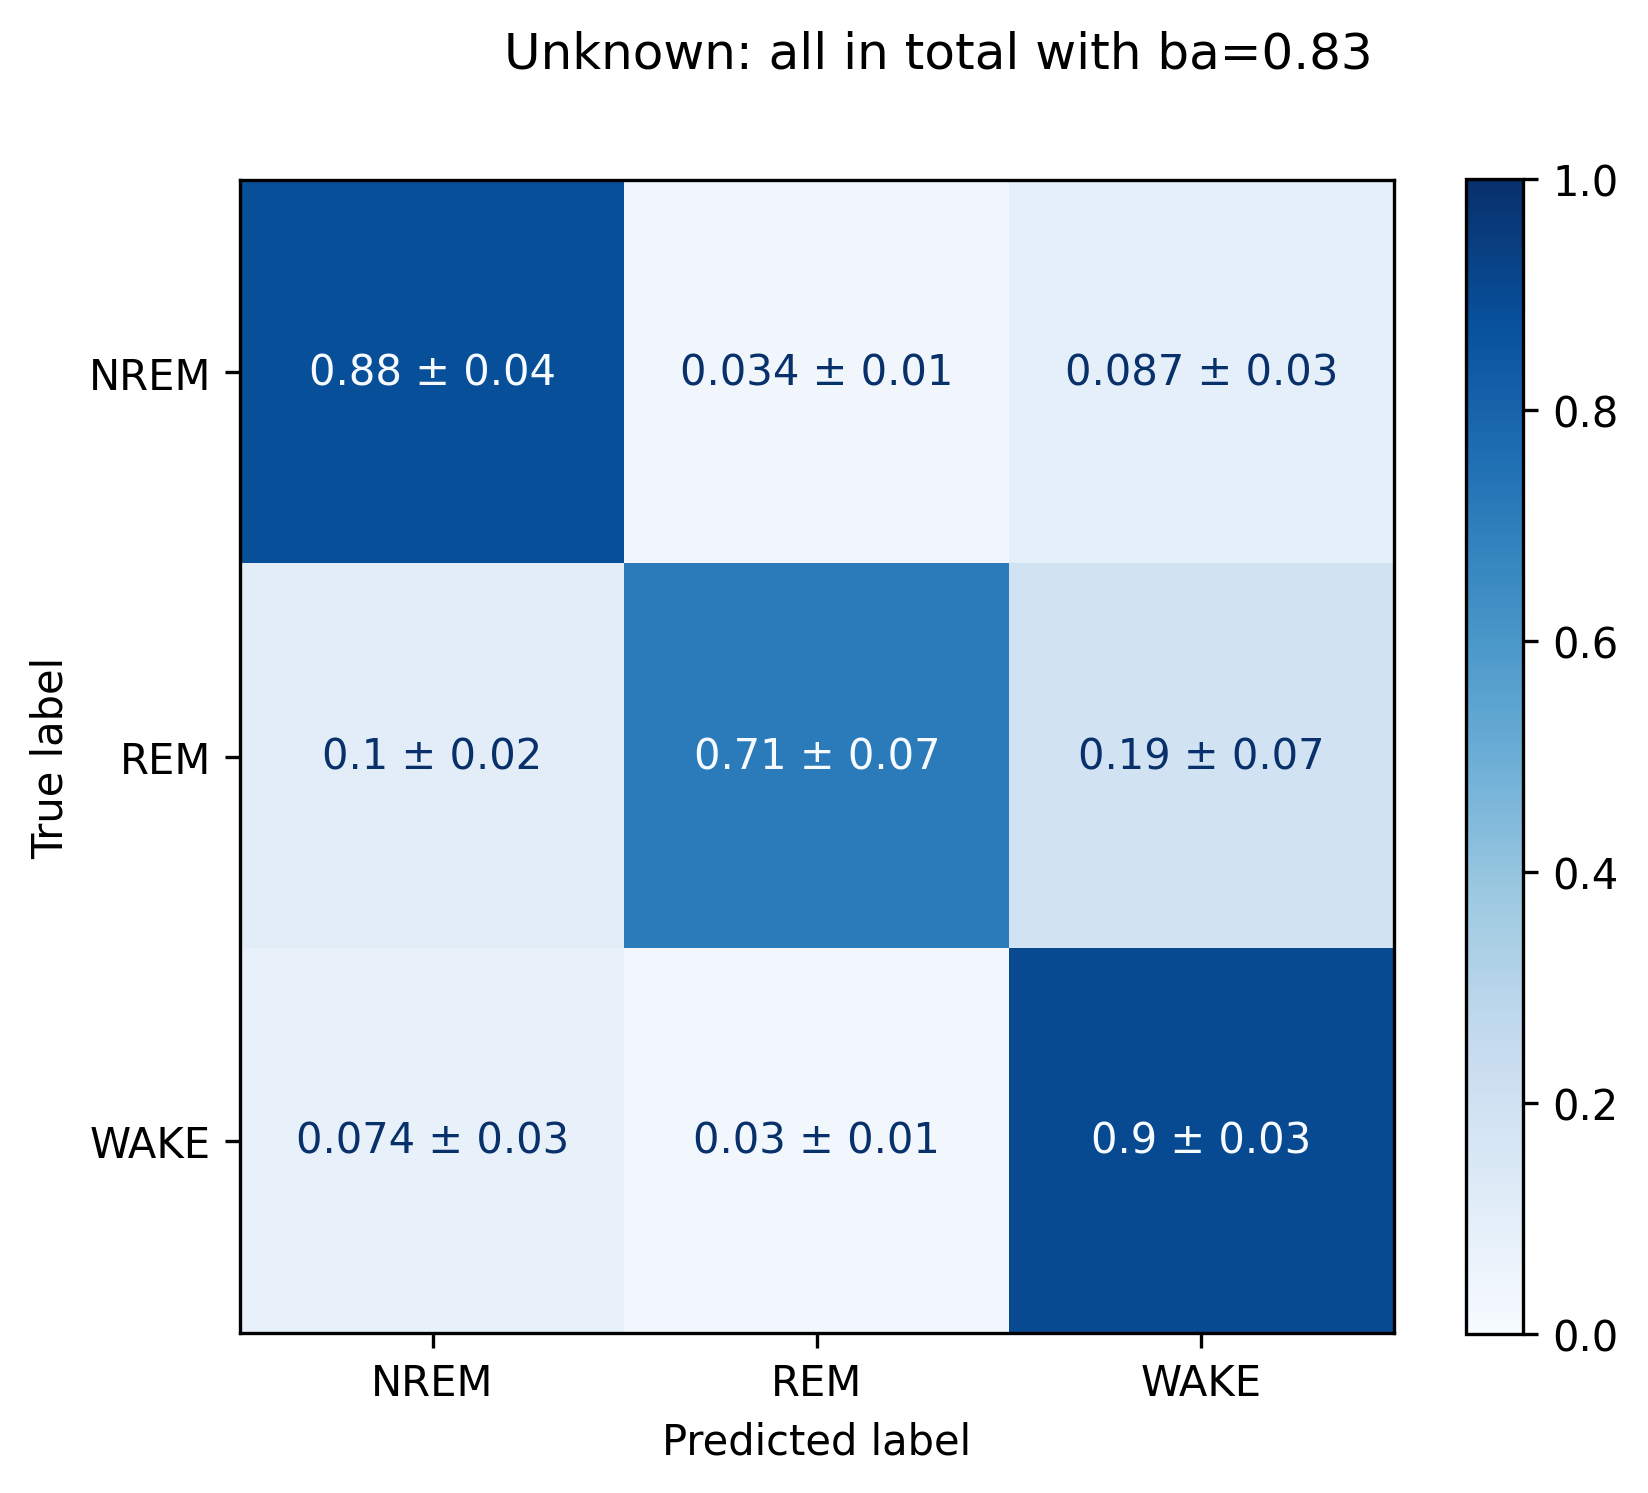

In [29]:
condensed = graphic_train.copy()[['animal', 'geno', 'age_group', 'age']].drop_duplicates(['animal'])
condensed['cell'] = condensed['animal']
#print(condensed)
get_mean_cms_visual(anim_cms, condensed, addon_text=False, by_geno=False, by_age=False, by_animal=False,
                   alt_se=True,subplot_kwargs={'figsize':(6.2,5), 'dpi':300})

In [33]:
condensed

,animal,geno,age_group,age,cell
0,caf69,wt,old,358,caf69
1098,caf71,app_ps1,old,492,caf71
1842,caf73,app_ps1,old,381,caf73
3009,caf74,app_ps1,old,419,caf74
3876,caf75,app_ps1,old,389,caf75
4803,caf77,wt,old,394,caf77
5139,caf81,wt,old,455,caf81
6408,caf82,wt,old,455,caf82
7038,zbr106,wt,young,101,zbr106
7763,zbr113,app_ps1,young,91,zbr113


In [44]:
out_df = {'geno':[], 'age':[], 'animal':[], 'balanced_acc':[], 'nrem_acc':[], 'rem_acc':[], 'wake_acc':[],'age_group':[]}
for animal in anim_cms:
    dat = condensed[condensed.animal==animal].iloc[0]
    out_df['geno'].append(dat.geno)
    out_df['age'].append(dat.age)
    out_df['age_group'].append(dat.age_group)
    out_df['animal'].append(animal)
    out_df['balanced_acc'].append(accuracy(anim_cms[animal]))
    out_df['nrem_acc'].append(anim_cms[animal][0][0])
    out_df['rem_acc'].append(anim_cms[animal][1][1])
    out_df['wake_acc'].append(anim_cms[animal][2][2])
out_df = pd.DataFrame(out_df)
out_df['cell'] = out_df['animal']

In [45]:
with open(f'/media/HlabShare/Toby_work/sleep_indiv_neuron/accuracy_dataframes/full_anim_log', 'wb') as f:
            pickle.dump(out_df, f)

In [ ]:
merge_accuracy_neuron()

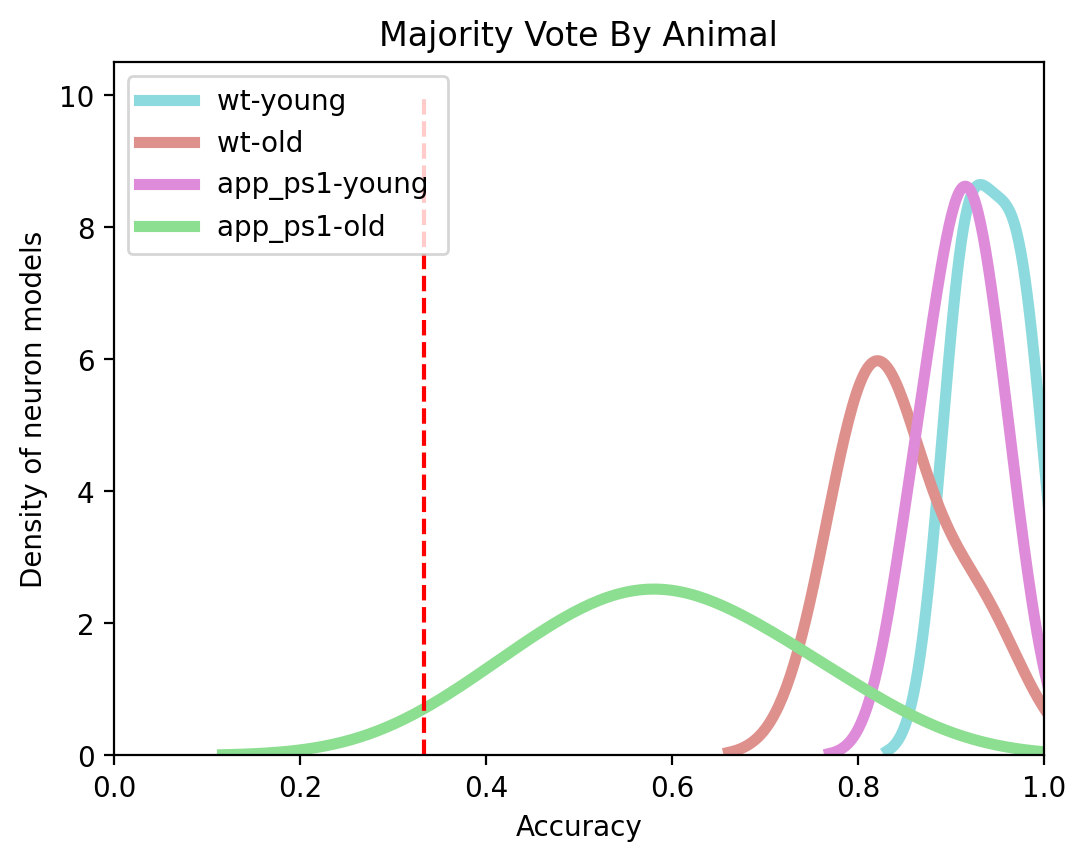

In [27]:
fig, ax = plt.subplots(1,1, dpi=200, figsize=(6,4.5))
get_cm_distrib_hist(anim_cms, condensed,"Majority Vote By Animal", by_geno=True, by_age=True, by_animal=False, 
                    kde=True, bw_adjust=1.1,
                   linewidth=4)

In [172]:
combined

,level_0,index,real,predictions,confidences,length,start,end,hits,pred_b,pred_c,pred_num,avg_conf,file,animal,geno,age,cell
0,0,54,1,"[2.0, 1.0, 2.0]","[1.4447566229462432, 0.47608608708179606, 1.19...",216.0,0.0,216.0,"[[0.12331999999878462, 53.693319999998494], [5...",0,0,5.0,"[0.7223783114731216, 0.47608608708179606, 0.59...",bth100_0624_0_12,bth100,wt,young,bth1000
1,1,62,1,"[19.0, 72.0, 14.0]","[11.814528477940382, 50.12065722960751, 9.3948...",68.0,3256.0,3324.0,"[[3256.0420799999993, 3276.25676], [3276.25676...",1,1,105.0,"[0.6218172883126517, 0.6961202393001042, 0.671...",bth100_0624_0_12,bth100,wt,young,bth1001
2,2,64,0,"[16.0, 3.0, 1.0]","[9.540656328668634, 1.2674600276830945, 0.3826...",408.0,3432.0,3840.0,"[[3432.066920000001, 3449.939760000001], [3449...",0,0,20.0,"[0.5962910205417896, 0.42248667589436484, 0.38...",bth100_0624_0_12,bth100,wt,young,bth1002
3,3,65,1,"[42.0, 105.0, 34.0]","[26.19097425638868, 71.98324221557735, 20.8145...",104.0,3840.0,3944.0,"[[3843.8943599999984, 3943.6046800000004], [38...",1,1,181.0,"[0.6235946251521115, 0.6855546877674034, 0.612...",bth100_0624_0_12,bth100,wt,young,bth1003
4,4,68,1,"[32.0, 66.0, 15.0]","[22.383357354217893, 48.314725021604396, 8.543...",48.0,4888.0,4936.0,"[[4890.625599999999, 4926.297760000001], [4890...",1,1,113.0,"[0.6994799173193091, 0.7320412882061272, 0.569...",bth100_0624_0_12,bth100,wt,young,bth1004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110,25,131,2,"[23.0, 32.0, 87.0]","[9.873912405550204, 16.09899130957996, 53.8611...",12.0,65740.0,65752.0,"[[65740.03008, 65751.57904], [65740.1258000000...",2,2,142.0,"[0.429300539371748, 0.5030934784243738, 0.6190...",caf69_1230_12_24,caf69,wt,old,caf69110
111,26,133,0,"[176.0, 204.0, 192.0]","[77.43640506517376, 89.14843319010113, 87.3928...",280.0,65880.0,66160.0,"[[65880.19632, 65985.44219999999], [65985.4421...",1,1,572.0,"[0.4399795742339418, 0.4370021234808879, 0.455...",caf69_1230_12_24,caf69,wt,old,caf69111
112,27,135,2,"[0.0, 1.0, 9.0]","[0.0, 0.513795671972627, 6.8927449150259354]",8.0,66392.0,66400.0,"[[66397.30836, 66398.31788], [66392.12552, 663...",2,2,10.0,"[0, 0.513795671972627, 0.7658605461139928]",caf69_1230_12_24,caf69,wt,old,caf69112
113,28,149,0,"[1953.0, 1250.0, 1014.0]","[864.8011474205272, 529.9814636585236, 453.960...",1560.0,67000.0,68560.0,"[[67000.32192, 67052.79664], [67052.79664, 671...",0,0,4217.0,"[0.4428065270970441, 0.42398517092681887, 0.44...",caf69_1230_12_24,caf69,wt,old,caf69113


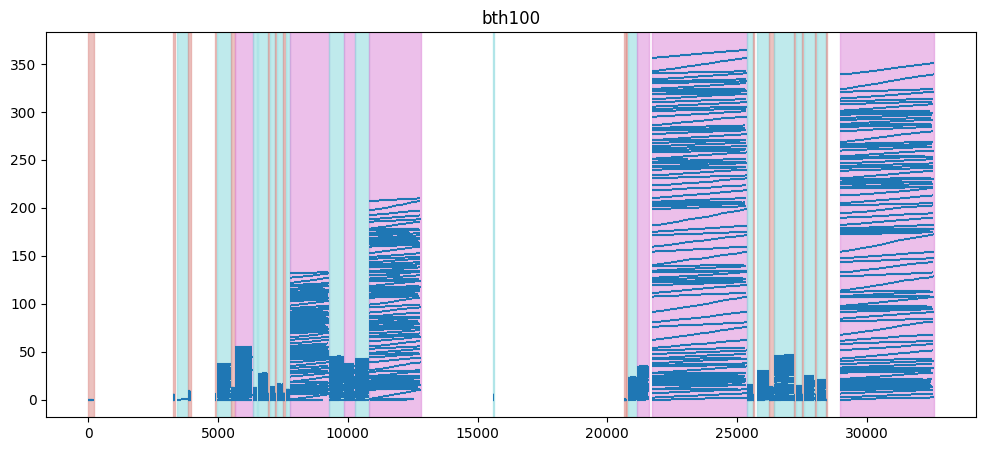

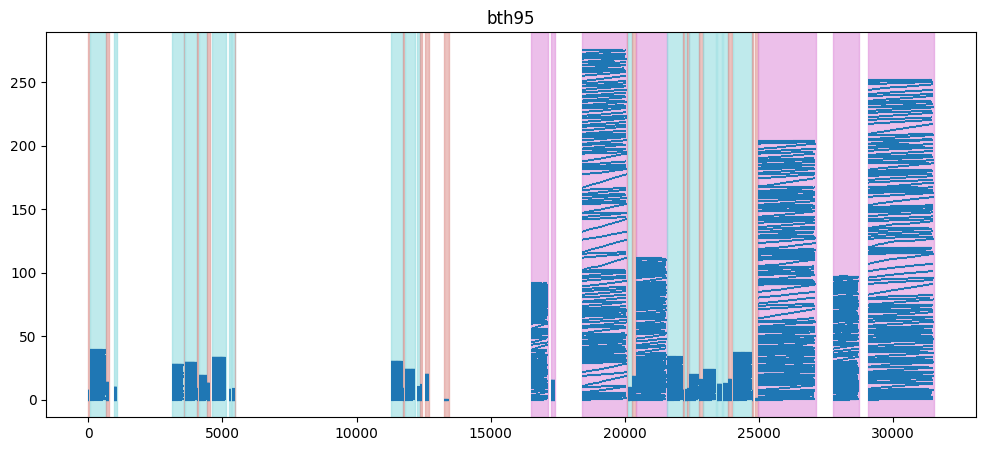

Error in callback <function flush_figures at 0x79de1c8059e0> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

In [180]:
for animal in combined.animal.unique():
    #print(animal)
    spec = combined[combined["animal"]==animal]
    fig, axes = plt.subplots(1,1, figsize=(12, 5))
    for i in range(len(spec)):
        axes.axvspan(spec.iloc[i].start, spec.iloc[i].end, color=ext_colors[spec.iloc[i].real])
        x = [x*0.05 for x in range(0,len(spec.iloc[i].hits))]
        y_s = [h[0] for h in spec.iloc[i].hits]
        y_e =  [h[1] for h in spec.iloc[i].hits]
        #print(x, y_s, y_e)
        plt.hlines(x, y_s, y_e)
    plt.title(animal)

In [30]:
combined

,level_0,index,real,predictions,confidences,length,start,end,pred_b,pred_c,pred_num,avg_conf,animal,geno,age,cell
0,0,62,1,"[19.0, 72.0, 14.0]","[11.814528477940382, 50.12065722960751, 9.3948...",68.0,21688.0,21756.0,1,1,105.0,"[0.6218172883126517, 0.6961202393001042, 0.671...",bth100,wt,young,bth1000
1,1,64,0,"[16.0, 3.0, 1.0]","[9.540656328668634, 1.2674600276830945, 0.3826...",408.0,21864.0,22272.0,0,0,20.0,"[0.5962910205417896, 0.42248667589436484, 0.38...",bth100,wt,young,bth1001
2,2,65,1,"[42.0, 105.0, 34.0]","[26.19097425638868, 71.98324221557735, 20.8145...",104.0,22272.0,22376.0,1,1,181.0,"[0.6235946251521115, 0.6855546877674034, 0.612...",bth100,wt,young,bth1002
3,3,68,1,"[32.0, 66.0, 15.0]","[22.383357354217893, 48.314725021604396, 8.543...",48.0,23320.0,23368.0,1,1,113.0,"[0.6994799173193091, 0.7320412882061272, 0.569...",bth100,wt,young,bth1003
4,4,70,0,"[481.0, 157.0, 107.0]","[356.7265264929595, 93.35662915618553, 61.5288...",532.0,23388.0,23920.0,0,0,745.0,"[0.7416351902140531, 0.5946282111858952, 0.575...",bth100,wt,young,bth1004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,22,129,2,"[16.0, 53.0, 79.0]","[6.384201601400837, 28.815248653346373, 47.619...",24.0,33704.0,33728.0,2,2,148.0,"[0.3990126000875523, 0.5436839368555919, 0.602...",caf69,wt,old,caf6996
97,23,131,2,"[23.0, 32.0, 87.0]","[9.873912405550204, 16.09899130957996, 53.8611...",12.0,33820.0,33832.0,2,2,142.0,"[0.429300539371748, 0.5030934784243738, 0.6190...",caf69,wt,old,caf6997
98,24,133,0,"[176.0, 204.0, 192.0]","[77.43640506517376, 89.14843319010113, 87.3928...",280.0,33960.0,34240.0,1,1,572.0,"[0.4399795742339418, 0.4370021234808879, 0.455...",caf69,wt,old,caf6998
99,25,149,0,"[1953.0, 1250.0, 1014.0]","[864.8011474205272, 529.9814636585236, 453.960...",1560.0,35080.0,36640.0,0,0,4217.0,"[0.4428065270970441, 0.42398517092681887, 0.44...",caf69,wt,old,caf6999


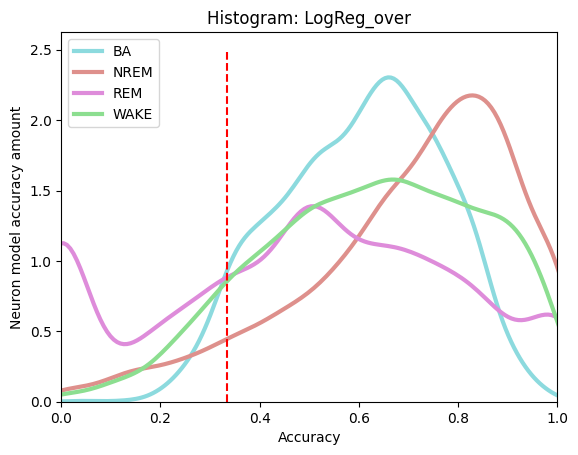

/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/poster/all/Histogram: LogReg_over.pdf


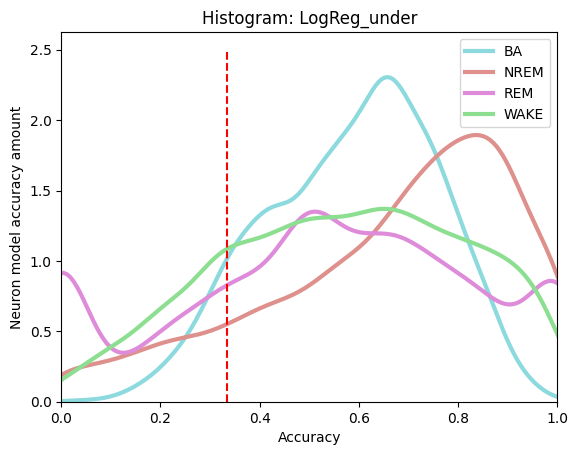

/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/poster/all/Histogram: LogReg_under.pdf


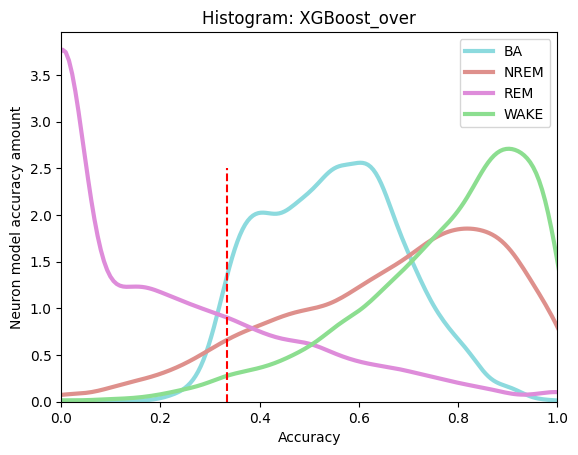

/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/poster/all/Histogram: XGBoost_over.pdf


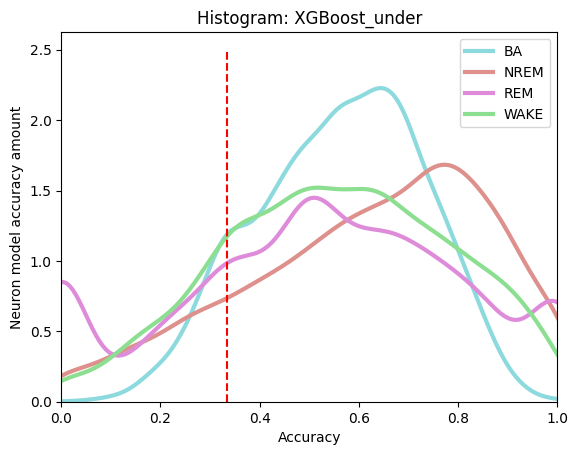

/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/poster/all/Histogram: XGBoost_under.pdf


In [73]:
plot_evs = [accuracy, lambda x:x[0][0], lambda x:x[1][1], lambda x:x[2][2]]
for key, val in cms.items():
    fig, ax = plt.subplots(1,1)
    cm_label = f"Histogram: {key}"
    get_cm_distrib_hist(val, graphic_train, cm_label, plot_eval=plot_evs, histtype='bar', linewidth=3, kde=True,)
    plt.legend(("BA", "NREM", "REM", "WAKE"))
    plt.vlines(1/3, 0, 2.5, color='r', ls='--')
    plt.xlim(0,1)
    plt.show()
    begin = '/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/'
    filename = f'{begin}poster/all/{cm_label}.pdf'
    print(filename)
    fig.savefig(filename,bbox_inches="tight")